# Heart Failure Survival Prediction System
**Project Developer:** Sahil  
**Roll Number:** 16  
**Course:** Machine Learning & Data Science Project  

---

## 1. Project Introduction

### 1.1 Project Objective
The objective of this project is to develop an educational machine learning application that analyzes structured clinical and medical measurements from a patient and predicts whether the patient's survival outcome is more likely to be:
- **Survived (0)**: Patient survived during the recorded follow-up observation window.
- **Death Event (1)**: Patient deceased during the recorded follow-up observation window.

> **Academic & Educational Disclaimer:**  
> This project is developed strictly for educational and academic purposes. It is **not** a clinical diagnostic instrument, a certified medical device, or a validated clinical prognosis calculator. It must never be used for actual clinical decisions, patient triage, or medical diagnosis.

### 1.2 Dataset Information
The dataset used in this project is the widely recognized **Heart Failure Clinical Records Dataset** (Davide Chicco & Giuseppe Jurman, *BMC Medical Informatics and Decision Making*, 2020), available via the UCI Machine Learning Repository. It comprises records from 299 patients with heart failure collected at the Allied Hospital in Faisalabad, Pakistan.

### 1.3 Target Variable
- **`DEATH_EVENT`**: Binary indicator where `0` denotes survival and `1` denotes mortality during the follow-up period.

### 1.4 Machine Learning Algorithms Implemented
1. **Random Forest Classifier**: An ensemble bagging algorithm combining multiple decision trees to capture nonlinear patterns and reduce variance.
2. **Logistic Regression (with StandardScaler)**: A linear probabilistic classification model equipped with L2 regularization and feature standardization.
3. **Decision Tree Classifier**: A rule-based tree model providing intuitive decision boundaries based on feature entropy and information gain.

### 1.5 Important Clinical Modeling Decision: Exclusion of `time`
The original dataset includes a column named `time`, which represents the follow-up observation window in days. In a real-world predictive scenario, when a new patient visits a clinic, their future follow-up duration is unknown. Including `time` as an input feature would introduce severe **target leakage** and artificially inflate accuracy. Therefore, following sound data science principles, the `time` column is intentionally excluded from all model training and user inputs.

## 2. Import Libraries

We import the essential Python libraries for data manipulation, visualization, machine learning, and model persistence:
- **pandas**: Tabular data manipulation and analysis.
- **numpy**: Numerical operations and array computing.
- **matplotlib & seaborn**: Data visualization, distributions, and heatmaps.
- **scikit-learn**: Data splitting, feature scaling, model training, cross-validation, and metrics.
- **joblib**: Model serialization for production deployment.

In [1]:
# Import core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

# Scikit-learn modules
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve
)

# Plotting configuration
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

print("All required libraries imported successfully!")

All required libraries imported successfully!


## 3. Load Dataset

We load the dataset from `data/heart_failure_clinical_records_dataset.csv` using pandas and inspect its fundamental characteristics:
1. `df.head()` - First 5 records
2. `df.tail()` - Last 5 records
3. `df.info()` - Column summaries and non-null counts
4. `df.shape` - Dimensions of the dataset (rows, columns)
5. `df.columns` - List of feature names
6. `df.dtypes` - Data types of each column
7. `df.isnull().sum()` - Missing value count per column
8. `df.duplicated().sum()` - Number of identical duplicate rows
9. `df.describe()` - Statistical summary of numerical variables
10. `df['DEATH_EVENT'].value_counts()` - Target variable distribution

In [2]:
# Load dataset
data_path = 'data/heart_failure_clinical_records_dataset.csv'
df = pd.read_csv(data_path)
print(f"Dataset successfully loaded from: {data_path}")

Dataset successfully loaded from: data/heart_failure_clinical_records_dataset.csv


In [3]:
# 1. Display first 5 rows
print("--- 1. First 5 Rows (head) ---")
df.head()

--- 1. First 5 Rows (head) ---


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [4]:
# 2. Display last 5 rows
print("--- 2. Last 5 Rows (tail) ---")
df.tail()

--- 2. Last 5 Rows (tail) ---


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
294,62.0,0,61,1,38,1,155000.0,1.1,143,1,1,270,0
295,55.0,0,1820,0,38,0,270000.0,1.2,139,0,0,271,0
296,45.0,0,2060,1,60,0,742000.0,0.8,138,0,0,278,0
297,45.0,0,2413,0,38,0,140000.0,1.4,140,1,1,280,0
298,50.0,0,196,0,45,0,395000.0,1.6,136,1,1,285,0


In [5]:
# 3. Display dataset information
print("--- 3. Dataset Info ---")
df.info()

--- 3. Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30

In [6]:
# 4. Display shape
print("--- 4. Dataset Shape (rows, columns) ---")
print("Shape:", df.shape)

# 5. Display column names
print("\n--- 5. Dataset Columns ---")
print(list(df.columns))

# 6. Display data types
print("\n--- 6. Column Data Types ---")
print(df.dtypes)

--- 4. Dataset Shape (rows, columns) ---
Shape: (299, 13)

--- 5. Dataset Columns ---
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time', 'DEATH_EVENT']

--- 6. Column Data Types ---
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object


In [7]:
# 7. Check for missing values
print("--- 7. Missing Values Count Per Column ---")
print(df.isnull().sum())

# 8. Check for duplicate rows
print("\n--- 8. Duplicate Rows Count ---")
print("Total duplicate rows:", df.duplicated().sum())

--- 7. Missing Values Count Per Column ---
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

--- 8. Duplicate Rows Count ---
Total duplicate rows: 0


In [8]:
# 9. Statistical summary
print("--- 9. Statistical Summary (describe) ---")
display(df.describe().T)

# 10. Target variable distribution
print("\n--- 10. Target Variable (DEATH_EVENT) Distribution ---")
print("Counts:\n", df['DEATH_EVENT'].value_counts())
print("\nNormalized Proportions:\n", df['DEATH_EVENT'].value_counts(normalize=True).round(4))

--- 9. Statistical Summary (describe) ---


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0



--- 10. Target Variable (DEATH_EVENT) Distribution ---
Counts:
 DEATH_EVENT
0    203
1     96
Name: count, dtype: int64

Normalized Proportions:
 DEATH_EVENT
0    0.6789
1    0.3211
Name: proportion, dtype: float64


## 4. Data Cleaning & Validation

In this section, we perform systematic data verification and cleaning checks according to clinical standards:
1. **Missing Values**: Verify that no values are missing in the dataset.
2. **Duplicate Records**: Confirm no duplicate rows exist.
3. **Data Types**: Ensure all features are stored in appropriate numeric formats (`int64` or `float64`).
4. **Value Ranges & Medical Sanity**: Check minimum, maximum, and realistic medical bounds for continuous measurements.
5. **Binary Columns**: Verify that binary flags (`anaemia`, `diabetes`, `high_blood_pressure`, `sex`, `smoking`, `DEATH_EVENT`) strictly take values in `{0, 1}`.
6. **Outlier Inspection**: Analyze extreme values in `creatinine_phosphokinase`, `serum_creatinine`, and `platelets`. In medical data, acute elevations often represent severe physiological distress (e.g., cardiogenic shock or acute kidney injury) rather than erroneous data entry; thus, records should be preserved.

In [9]:
# 4.1 Missing values check
missing_total = df.isnull().sum().sum()
print(f"Total missing values in entire dataset: {missing_total}")
assert missing_total == 0, "Missing values found!"

# 4.2 Duplicate records check
duplicate_total = df.duplicated().sum()
print(f"Total duplicate rows: {duplicate_total}")
if duplicate_total > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")
else:
    print("No duplicates detected. Dataset is clean.")

# 4.3 Verify binary columns
binary_cols = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'DEATH_EVENT']
print("\n--- Binary Columns Verification ---")
for col in binary_cols:
    unique_vals = sorted(df[col].unique().tolist())
    print(f"Column '{col}': unique values = {unique_vals}")
    assert unique_vals == [0, 1], f"Unexpected values in {col}"

# 4.4 Value Range Verification
print("\n--- Numerical Feature Range Verification ---")
num_cols = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets', 'serum_creatinine', 'serum_sodium']
for col in num_cols:
    print(f"{col:25s} -> Min: {df[col].min():8.1f} | Median: {df[col].median():8.1f} | Max: {df[col].max():8.1f}")

# 4.5 Outlier Assessment via IQR method
print("\n--- Outlier Count (IQR Method) ---")
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
    print(f"{col:25s}: {len(outliers):2d} potential statistical outliers")

print("\nMedical note on outliers: High values in CPK (up to 7861 mcg/L) and serum creatinine (up to 9.4 mg/dL) "
      "reflect severe clinical manifestations (acute myocardial injury and renal failure) in heart failure patients. "
      "These represent genuine clinical signals rather than measurement errors, so they are retained.")

Total missing values in entire dataset: 0
Total duplicate rows: 0
No duplicates detected. Dataset is clean.

--- Binary Columns Verification ---
Column 'anaemia': unique values = [0, 1]
Column 'diabetes': unique values = [0, 1]
Column 'high_blood_pressure': unique values = [0, 1]
Column 'sex': unique values = [0, 1]
Column 'smoking': unique values = [0, 1]
Column 'DEATH_EVENT': unique values = [0, 1]

--- Numerical Feature Range Verification ---
age                       -> Min:     40.0 | Median:     60.0 | Max:     95.0
creatinine_phosphokinase  -> Min:     23.0 | Median:    250.0 | Max:   7861.0
ejection_fraction         -> Min:     14.0 | Median:     38.0 | Max:     80.0
platelets                 -> Min:  25100.0 | Median: 262000.0 | Max: 850000.0
serum_creatinine          -> Min:      0.5 | Median:      1.1 | Max:      9.4
serum_sodium              -> Min:    113.0 | Median:    137.0 | Max:    148.0

--- Outlier Count (IQR Method) ---
age                      :  0 potential statis

## 5. Exploratory Data Analysis (EDA)

We create focused, uncluttered visualizations to reveal the primary patterns and correlations in the clinical data:
1. **Target Distribution**: Bar chart of patient survival outcomes (`DEATH_EVENT`).
2. **Histograms of Key Clinical Variables**: Distributions of `age`, `ejection_fraction`, and `serum_creatinine`.
3. **Correlation Heatmap**: Pearson correlation between clinical features and mortality.
4. **Grouped Boxplots**: Comparison of `ejection_fraction` and `serum_creatinine` stratified by patient survival.

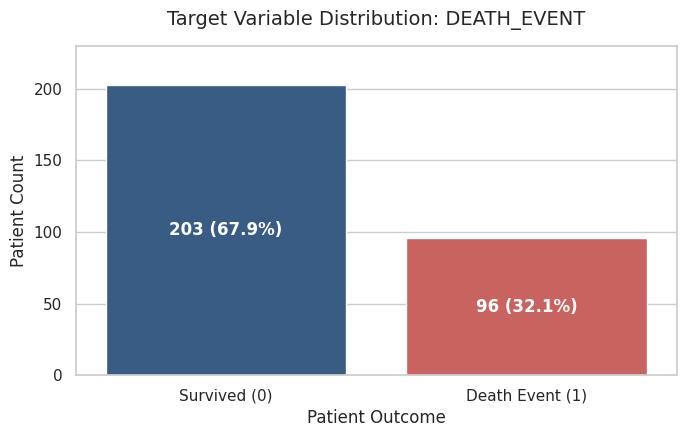

In [10]:
# Graph 1: Target Variable Distribution
plt.figure(figsize=(7, 4.5))
palette = ['#2b5c8f', '#d9534f']
ax = sns.countplot(x='DEATH_EVENT', hue='DEATH_EVENT', data=df, palette=palette, dodge=False, legend=False)

# Annotate bars with counts and percentages
total = len(df)
for p in ax.patches:
    count = int(p.get_height())
    pct = (count / total) * 100
    ax.annotate(f"{count} ({pct:.1f}%)", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.title('Target Variable Distribution: DEATH_EVENT', fontsize=14, pad=15)
plt.xlabel('Patient Outcome', fontsize=12)
plt.ylabel('Patient Count', fontsize=12)
plt.xticks([0, 1], ['Survived (0)', 'Death Event (1)'])
plt.ylim(0, 230)
plt.tight_layout()
plt.show()

**Explanation of Graph 1:**  
The target variable exhibits moderate class imbalance: 203 patients (67.9%) survived during their follow-up period, while 96 patients (32.1%) experienced a death event. To prevent models from being biased toward the majority class (Survived), we use `class_weight='balanced'` during model training.

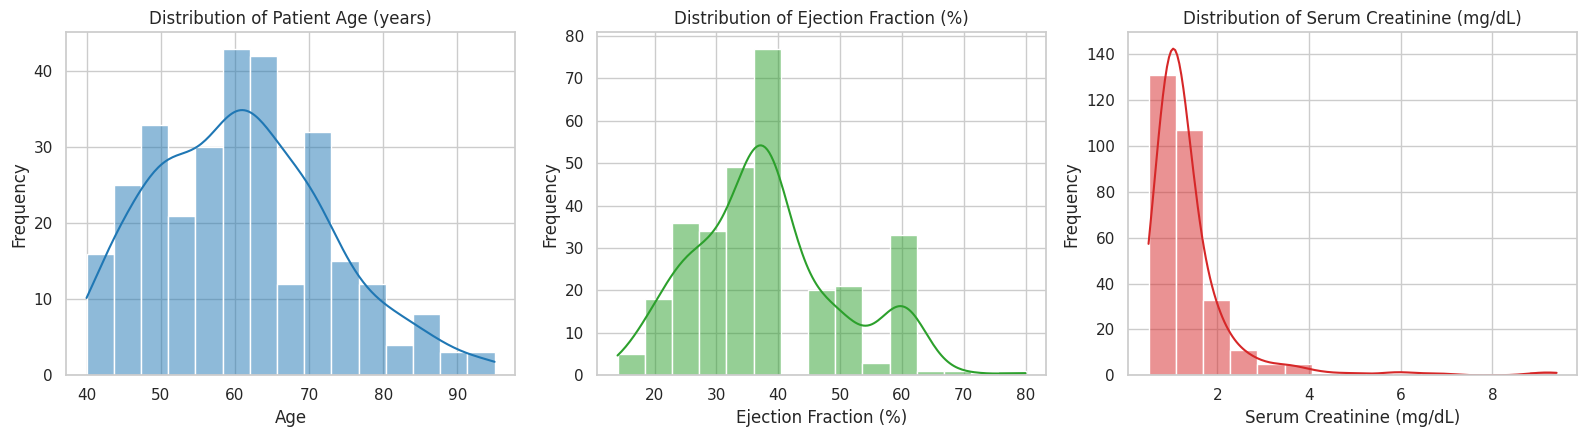

In [11]:
# Graph 2: Histograms of Key Numerical Columns
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Age distribution
sns.histplot(df['age'], kde=True, ax=axes[0], color='#1f77b4', bins=15)
axes[0].set_title('Distribution of Patient Age (years)', fontsize=12)
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frequency')

# Ejection Fraction distribution
sns.histplot(df['ejection_fraction'], kde=True, ax=axes[1], color='#2ca02c', bins=15)
axes[1].set_title('Distribution of Ejection Fraction (%)', fontsize=12)
axes[1].set_xlabel('Ejection Fraction (%)')
axes[1].set_ylabel('Frequency')

# Serum Creatinine distribution
sns.histplot(df['serum_creatinine'], kde=True, ax=axes[2], color='#d62728', bins=15)
axes[2].set_title('Distribution of Serum Creatinine (mg/dL)', fontsize=12)
axes[2].set_xlabel('Serum Creatinine (mg/dL)')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

**Explanation of Graph 2:**  
- **Age**: Follows a roughly normal distribution centered around 60 years (range: 40 to 95). Heart failure risk increases with advancing age.
- **Ejection Fraction (%)**: Shows that most heart failure patients have reduced ejection fraction (<40%, indicating systolic heart failure).
- **Serum Creatinine (mg/dL)**: Shows a right-skewed distribution. While normal levels are typically 0.8–1.3 mg/dL, several patients exhibit severe elevations above 2.0 mg/dL, reflecting kidney dysfunction.

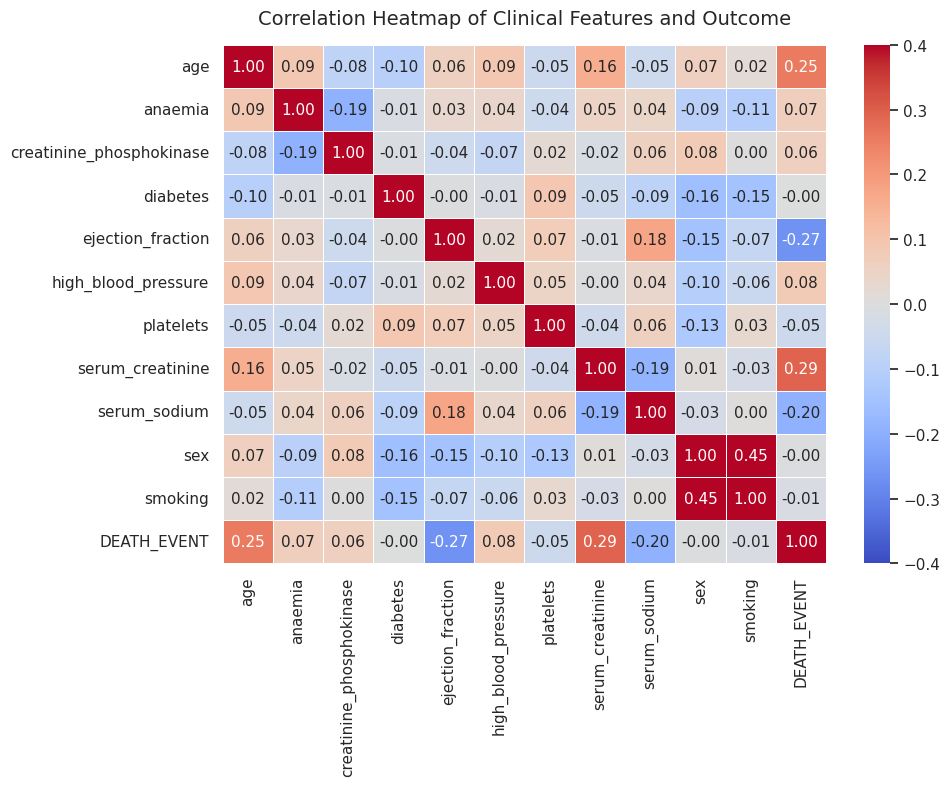

In [12]:
# Graph 3: Correlation Heatmap
# Exclude 'time' to focus on baseline clinical predictors
clinical_cols = [
    'age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
    'ejection_fraction', 'high_blood_pressure', 'platelets',
    'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'DEATH_EVENT'
]

plt.figure(figsize=(10, 8))
corr_matrix = df[clinical_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.4, vmax=0.4, linewidths=0.5)
plt.title('Correlation Heatmap of Clinical Features and Outcome', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

**Explanation of Graph 3:**  
- `serum_creatinine` (+0.29) and `age` (+0.25) have the strongest positive correlations with `DEATH_EVENT`.
- `ejection_fraction` (-0.27) and `serum_sodium` (-0.20) exhibit strong negative correlations with mortality (higher heart pumping efficiency and normal sodium levels are protective).
- Binary flags (`smoking`, `diabetes`, `sex`, `anaemia`) have low direct linear correlations, indicating that nonlinear interactions or multivariable combinations may be required to capture their predictive value.

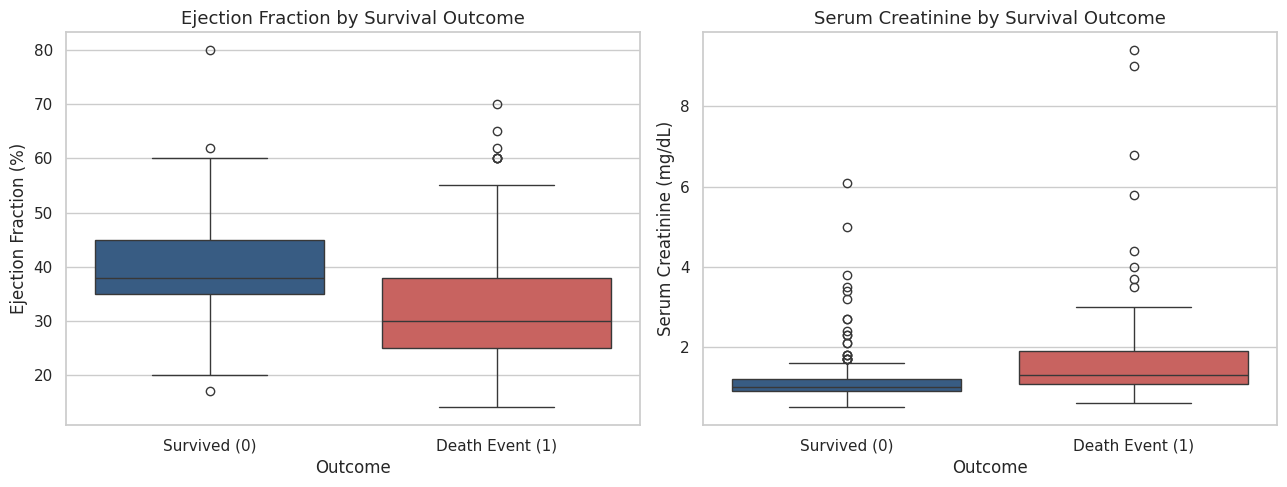

In [13]:
# Graph 4: Key Clinical Biomarkers Grouped by Patient Outcome
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

palette = ['#2b5c8f', '#d9534f']
sns.boxplot(x='DEATH_EVENT', y='ejection_fraction', hue='DEATH_EVENT', data=df, ax=axes[0], palette=palette, dodge=False, legend=False)
axes[0].set_title('Ejection Fraction by Survival Outcome', fontsize=13)
axes[0].set_xlabel('Outcome')
axes[0].set_ylabel('Ejection Fraction (%)')
axes[0].set_xticklabels(['Survived (0)', 'Death Event (1)'])

sns.boxplot(x='DEATH_EVENT', y='serum_creatinine', hue='DEATH_EVENT', data=df, ax=axes[1], palette=palette, dodge=False, legend=False)
axes[1].set_title('Serum Creatinine by Survival Outcome', fontsize=13)
axes[1].set_xlabel('Outcome')
axes[1].set_ylabel('Serum Creatinine (mg/dL)')
axes[1].set_xticklabels(['Survived (0)', 'Death Event (1)'])

plt.tight_layout()
plt.show()

**Explanation of Graph 4:**  
The grouped boxplots highlight clear clinical separation between outcomes:
- Patients who died had noticeably lower ejection fractions (median ~30%) compared to survivors (median ~38%).
- Patients who died had notably higher serum creatinine levels (median ~1.4 mg/dL) compared to survivors (median ~1.0 mg/dL), affirming that cardiorenal syndrome is a primary determinant of survival.

## 6. Feature Selection and Preprocessing

### 6.1 Feature Selection
We define:
- **Target Variable ($y$)**: `DEATH_EVENT`
- **Predictor Features ($X$)**: The 11 baseline clinical features:
  1. `age`
  2. `anaemia`
  3. `creatinine_phosphokinase`
  4. `diabetes`
  5. `ejection_fraction`
  6. `high_blood_pressure`
  7. `platelets`
  8. `serum_creatinine`
  9. `serum_sodium`
  10. `sex`
  11. `smoking`

> **Note on Data Leakage Prevention:**  
> The `time` column represents the post-admission follow-up duration (in days) during which the patient was monitored. Because follow-up time cannot be known when evaluating a new patient at baseline admission, including `time` would be target leakage. We strictly exclude `time`.

### 6.2 Train-Test Split
We split the dataset into 80% training data (239 samples) and 20% testing data (60 samples) using:
- `random_state=42` for reproducibility.
- `stratify=y` to maintain identical class ratios in both splits.

### 6.3 Feature Scaling
- **Logistic Regression**: Sensitive to feature magnitude differences (e.g. `platelets` in hundreds of thousands vs `serum_creatinine` around 1.0). We use `StandardScaler` inside a scikit-learn `Pipeline`.
- **Tree-based models (Random Forest, Decision Tree)**: Invariant to monotonic feature scaling, so they train directly on unscaled features.

In [14]:
# Define feature columns and target
feature_cols = [
    'age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
    'ejection_fraction', 'high_blood_pressure', 'platelets',
    'serum_creatinine', 'serum_sodium', 'sex', 'smoking'
]
target_col = 'DEATH_EVENT'

X = df[feature_cols]
y = df[target_col]

print(f"Features list ({len(feature_cols)} features):\n{feature_cols}")
print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")

# Perform 80:20 Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("\n--- Train / Test Split Breakdown ---")
print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"  - Survived (0): {(y_train == 0).sum()} | Death Event (1): {(y_train == 1).sum()}")
print(f"Testing set:  {X_test.shape[0]} samples ({X_test.shape[0]/len(df)*100:.1f}%)")
print(f"  - Survived (0): {(y_test == 0).sum()} | Death Event (1): {(y_test == 1).sum()}")

Features list (11 features):
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking']
Feature matrix shape: (299, 11)
Target vector shape: (299,)

--- Train / Test Split Breakdown ---
Training set: 239 samples (79.9%)
  - Survived (0): 162 | Death Event (1): 77
Testing set:  60 samples (20.1%)
  - Survived (0): 41 | Death Event (1): 19


## 7. Model Training

We train three classification algorithms suited for medical tabular data. To handle class imbalance, all three models incorporate `class_weight='balanced'`.

### Algorithm Overviews:
1. **Random Forest Classifier**:
   - An ensemble of randomized decision trees that aggregates predictions to mitigate overfitting and capture complex non-linear relationships.
   - Parameters: `n_estimators=100`, `max_depth=5`, `random_state=42`, `class_weight='balanced'`.
2. **Logistic Regression (with StandardScaler Pipeline)**:
   - A linear classification model that fits a log-odds function to estimate event probabilities.
   - Wrapped inside a `Pipeline` containing `StandardScaler` to ensure unbiased regularization.
   - Parameters: `max_iter=1000`, `random_state=42`, `class_weight='balanced'`.
3. **Decision Tree Classifier**:
   - A single interpretable decision tree that partitions the feature space using orthogonal splits.
   - Parameters: `max_depth=4`, `random_state=42`, `class_weight='balanced'`.

### 5-Fold Stratified Cross-Validation:
We perform 5-fold Stratified Cross-Validation on the **training set** (`X_train`, `y_train`) to measure each model's ability to identify high-risk patients (`DEATH_EVENT = 1`) using the **F1-score for class 1**.

In [15]:
# Define models

# Model 1: Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42,
    class_weight='balanced'
)

# Model 2: Logistic Regression (StandardScaler + LogisticRegression Pipeline)
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42,
        class_weight='balanced'
    ))
])

# Model 3: Decision Tree Classifier
dt_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42,
    class_weight='balanced'
)

models = {
    'Random Forest Classifier': rf_model,
    'Logistic Regression': lr_pipeline,
    'Decision Tree Classifier': dt_model
}

# Setup 5-fold Stratified Cross-Validation on training data
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}
print("--- 5-Fold Stratified Cross-Validation (F1-score for DEATH_EVENT=1) ---")
for name, model in models.items():
    # Evaluate using F1-score for minority positive class
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')
    cv_results[name] = {
        'mean_f1': scores.mean(),
        'std_f1': scores.std(),
        'scores': scores
    }
    print(f"\n{name}:")
    print(f"  Mean F1: {scores.mean():.4f} (+/- {scores.std():.4f})")
    print(f"  Fold F1 Scores: {[round(s, 4) for s in scores]}")

--- 5-Fold Stratified Cross-Validation (F1-score for DEATH_EVENT=1) ---



Random Forest Classifier:
  Mean F1: 0.5711 (+/- 0.0722)
  Fold F1 Scores: [np.float64(0.5714), np.float64(0.5833), np.float64(0.6875), np.float64(0.5517), np.float64(0.4615)]

Logistic Regression:
  Mean F1: 0.6687 (+/- 0.0279)
  Fold F1 Scores: [np.float64(0.6842), np.float64(0.6897), np.float64(0.6667), np.float64(0.6154), np.float64(0.6875)]

Decision Tree Classifier:
  Mean F1: 0.5134 (+/- 0.0976)
  Fold F1 Scores: [np.float64(0.5294), np.float64(0.6897), np.float64(0.4865), np.float64(0.4615), np.float64(0.4)]


## 8. Model Evaluation

In this section, we train all three candidate models on the complete training set (`X_train`, `y_train`) and evaluate them on the held-out test set (`X_test`, `y_test`).

We compute:
- **Accuracy**: Overall fraction of correct predictions.
- **Precision**: Fraction of predicted death events that were actual death events.
- **Recall (Sensitivity)**: Fraction of actual death events correctly identified.
- **F1-Score**: Harmonic mean of Precision and Recall.
- **ROC-AUC**: Area under the Receiver Operating Characteristic curve.

We also present:
- Comprehensive metrics comparison table.
- Classification reports.
- Confusion matrices.
- Actual vs. predicted outcomes table.

In [16]:
# Train and evaluate all models on the held-out test set
test_metrics = []
test_predictions = {'Actual': y_test.values}
test_probabilities = {}

for name, model in models.items():
    # Fit model on training set
    model.fit(X_train, y_train)
    
    # Predict outcomes and probabilities on test set
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    test_predictions[f"{name} Prediction"] = y_pred
    test_probabilities[name] = y_proba
    
    # Calculate performance metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)
    
    test_metrics.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(roc_auc, 4),
        'CV Mean F1': round(cv_results[name]['mean_f1'], 4)
    })

# Summary Comparison Table
results_df = pd.DataFrame(test_metrics)
print("=== Model Performance Comparison Table ===")
display(results_df)

=== Model Performance Comparison Table ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Mean F1
0,Random Forest Classifier,0.7167,0.5714,0.4211,0.4848,0.7702,0.5711
1,Logistic Regression,0.7000,0.5263,0.5263,0.5263,0.7343,0.6687
2,Decision Tree Classifier,0.7167,0.5385,0.7368,0.6222,0.7439,0.5134



==================== Random Forest Classifier ====================
                 precision    recall  f1-score   support

   Survived (0)       0.76      0.85      0.80        41
Death Event (1)       0.57      0.42      0.48        19

       accuracy                           0.72        60
      macro avg       0.67      0.64      0.64        60
   weighted avg       0.70      0.72      0.70        60


==================== Logistic Regression ====================
                 precision    recall  f1-score   support

   Survived (0)       0.78      0.78      0.78        41
Death Event (1)       0.53      0.53      0.53        19

       accuracy                           0.70        60
      macro avg       0.65      0.65      0.65        60
   weighted avg       0.70      0.70      0.70        60


==================== Decision Tree Classifier ====================
                 precision    recall  f1-score   support

   Survived (0)       0.85      0.71      0.77       

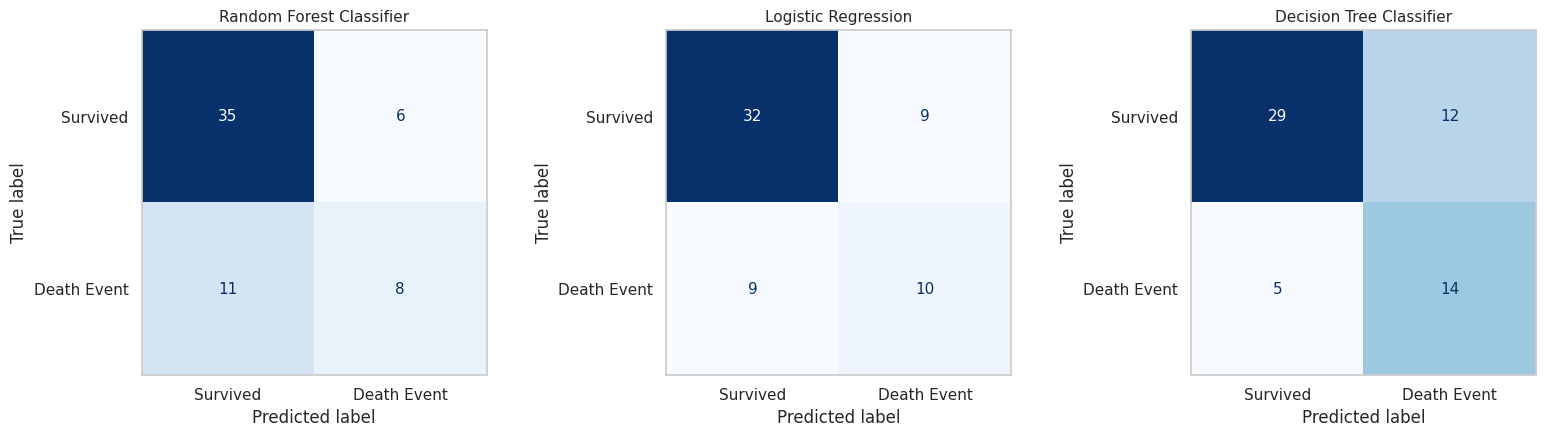

In [17]:
# Display Classification Reports and Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, (name, model) in enumerate(models.items()):
    y_pred = test_predictions[f"{name} Prediction"]
    print(f"\n==================== {name} ====================")
    print(classification_report(y_test, y_pred, target_names=['Survived (0)', 'Death Event (1)']))
    
    # Confusion Matrix Display
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Survived', 'Death Event'])
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f"{name}", fontsize=11)
    axes[i].grid(False)

plt.tight_layout()
plt.show()

In [18]:
# Create Actual vs Predicted DataFrame
comparison_df = pd.DataFrame(test_predictions, index=X_test.index)
print("=== Actual vs. Predicted Outcomes (Sample of First 15 Test Records) ===")
display(comparison_df.head(15))

=== Actual vs. Predicted Outcomes (Sample of First 15 Test Records) ===


,Actual,Random Forest Classifier Prediction,Logistic Regression Prediction,Decision Tree Classifier Prediction
274,0,0,1,0
149,0,0,0,0
120,0,0,0,1
226,0,1,1,1
125,0,0,0,0
298,0,0,0,1
130,0,0,0,0
110,1,0,0,1
275,0,0,0,0
190,0,1,1,1


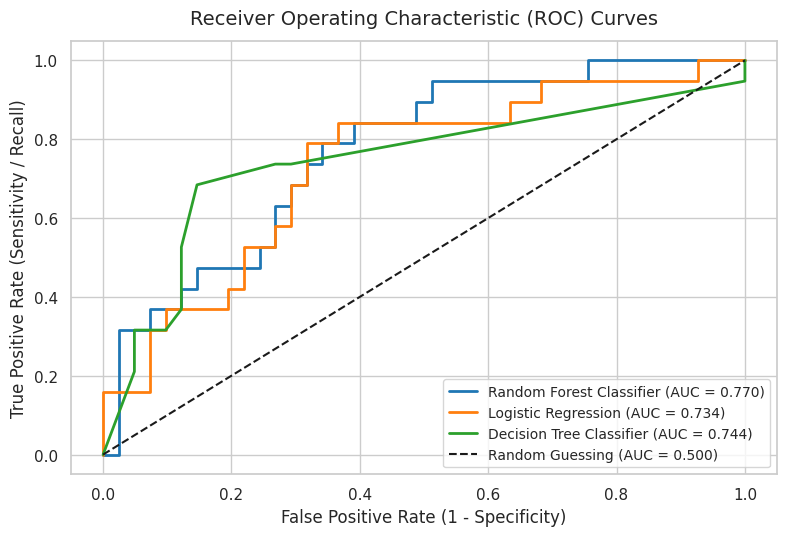

In [19]:
# Plot ROC Curves for all three models
plt.figure(figsize=(8, 5.5))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for (name, probas), color in zip(test_probabilities.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, probas)
    auc = roc_auc_score(y_test, probas)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", color=color, linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.500)')
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=14, pad=12)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()

In [20]:
# Select the best model dynamically using mean cross-validation F1-score
cv_summary = pd.DataFrame([
    {
        "Model": name,
        "Mean CV F1-Score": result["mean_f1"],
        "CV F1 Std": result["std_f1"]
    }
    for name, result in cv_results.items()
]).sort_values("Mean CV F1-Score", ascending=False).reset_index(drop=True)

print("=== Cross-Validation Model Ranking ===")
display(cv_summary)

best_model_name = max(cv_results, key=lambda name: cv_results[name]["mean_f1"])
best_model = models[best_model_name]
best_cv_f1 = float(cv_results[best_model_name]["mean_f1"])
best_cv_std = float(cv_results[best_model_name]["std_f1"])
best_test_metrics = results_df.loc[results_df["Model"] == best_model_name].iloc[0].to_dict()

print(f"Selected best model: {best_model_name}")
print(f"Mean 5-fold CV F1-score: {best_cv_f1:.4f} (+/- {best_cv_std:.4f})")
print("Held-out test metrics:")
display(pd.DataFrame([best_test_metrics]))


=== Cross-Validation Model Ranking ===


,Model,Mean CV F1-Score,CV F1 Std
0,Logistic Regression,0.668683,0.027856
1,Random Forest Classifier,0.571105,0.072219
2,Decision Tree Classifier,0.513418,0.097566


Selected best model: Logistic Regression
Mean 5-fold CV F1-score: 0.6687 (+/- 0.0279)
Held-out test metrics:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Mean F1
0,Logistic Regression,0.7,0.5263,0.5263,0.5263,0.7343,0.6687


## 9. Save Best Model

The best estimator is selected automatically from the three candidates using the highest mean 5-fold stratified cross-validation F1-score for `DEATH_EVENT = 1`. The selected estimator is then saved with `joblib`. For Logistic Regression, the saved estimator includes its `StandardScaler` preprocessing pipeline. The saved artifact also records the feature order, target name, evaluation metrics, and library versions so the Streamlit app can check compatibility.


In [21]:
# Create an artifact containing the selected trained model and metadata
model_artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_names": feature_cols,
    "target_name": target_col,
    "cv_f1_score": best_cv_f1,
    "cv_f1_std": best_cv_std,
    "test_metrics": best_test_metrics,
    "sklearn_version": __import__("sklearn").__version__,
    "python_version": __import__("sys").version.split()[0],
    "dataset_file": "heart_failure_clinical_records_dataset.csv"
}

# Save the selected model artifact in the project folder
model_filename = "best_model.joblib"
joblib.dump(model_artifact, model_filename)
print(f"Best model artifact saved successfully as: {model_filename}")

# Reload the artifact and verify that it can make a prediction
loaded_artifact = joblib.load(model_filename)
assert loaded_artifact["feature_names"] == feature_cols
sample_input = X_test.iloc[[0]][feature_cols]
sample_prediction = loaded_artifact["model"].predict(sample_input)[0]
sample_probabilities = loaded_artifact["model"].predict_proba(sample_input)[0]

print("\n--- Saved Model Verification ---")
print("Model:", loaded_artifact["model_name"])
print("scikit-learn version:", loaded_artifact["sklearn_version"])
print("Feature count:", len(loaded_artifact["feature_names"]))
print("Sample prediction:", int(sample_prediction))
print(f"P(DEATH_EVENT=0): {sample_probabilities[0]:.4f}")
print(f"P(DEATH_EVENT=1): {sample_probabilities[1]:.4f}")
print("Saved model verification completed successfully.")


Best model artifact saved successfully as: best_model.joblib

--- Saved Model Verification ---
Model: Logistic Regression
scikit-learn version: 1.8.0
Feature count: 11
Sample prediction: 1
P(DEATH_EVENT=0): 0.3661
P(DEATH_EVENT=1): 0.6339
Saved model verification completed successfully.


## 10. Conclusion

### 10.1 Summary of Work Performed
1. **Dataset analysis:** The dataset contains 299 heart-failure patient records and 13 original columns. The target `DEATH_EVENT` has 203 records labelled 0 and 96 records labelled 1.
2. **Data cleaning:** Missing values and duplicate records were checked. The supplied dataset has no missing values or duplicate rows. Potential statistical outliers were inspected and retained because extreme clinical measurements may be meaningful.
3. **EDA:** A target distribution chart, numerical histograms, a correlation heatmap, and a small set of outcome comparisons were used to understand the data.
4. **Feature selection:** Eleven baseline clinical features were used. The `time` column was excluded because it describes the follow-up period and would not be available as a baseline input.
5. **Model comparison:** Random Forest, Logistic Regression, and Decision Tree classifiers were compared using stratified cross-validation and held-out test metrics.
6. **Best model:** The model with the highest mean cross-validation F1-score for class 1 was selected automatically. Its actual cross-validation and test results are printed in the model-selection section above.
7. **Model saving:** The selected fitted model, preprocessing (where applicable), feature order, evaluation metrics, and library-version information were saved in `best_model.joblib`.

### 10.2 Project Limitations
- The dataset is small (299 records) and represents a limited patient cohort.
- The model has not been clinically validated and may not generalize to other populations or healthcare settings.
- The model predicts the recorded `DEATH_EVENT` label from the dataset; it does not estimate an individual's lifespan or guarantee a real-world survival outcome.
- This project is for education only and must not be used for diagnosis or treatment decisions.


In [22]:
# Final project result summary (values are generated from this notebook run)
print("PROJECT RESULT SUMMARY")
print("=" * 50)
print(f"Selected model: {best_model_name}")
print(f"Mean 5-fold CV F1-score: {best_cv_f1:.4f}")
print(f"Held-out test accuracy: {float(best_test_metrics['Accuracy']):.4f}")
print(f"Held-out test precision: {float(best_test_metrics['Precision']):.4f}")
print(f"Held-out test recall: {float(best_test_metrics['Recall']):.4f}")
print(f"Held-out test F1-score: {float(best_test_metrics['F1-Score']):.4f}")
print(f"Held-out test ROC-AUC: {float(best_test_metrics['ROC-AUC']):.4f}")
print("\nThe saved artifact is ready for the Streamlit application.")


PROJECT RESULT SUMMARY
Selected model: Logistic Regression
Mean 5-fold CV F1-score: 0.6687
Held-out test accuracy: 0.7000
Held-out test precision: 0.5263
Held-out test recall: 0.5263
Held-out test F1-score: 0.5263
Held-out test ROC-AUC: 0.7343

The saved artifact is ready for the Streamlit application.
